# Notebook 4 of 5: Filling a trench, and catching voids

**Goal:** understand the project's 2D model of filling a trench etched into a wafer: how atoms fall and stick, how
heat lets them move into better spots, how the code finds trapped empty pockets (**voids**) with a **flood fill**,
and how it measures **step coverage** and **film density**. We then reproduce the saved sweeps and read the trench
**process window** behind the recommended recipe.

## How to use this notebook

| | |
|---|---|
| **Prerequisites** | Notebook 3 (temperature, `epsilon`, hops per atom, Arrhenius, POR). Notebooks 1 and 2 help but are not required. |
| **Kernel** | *Thin Film Growth* (`thin-film-growth`, the project's `.venv`). |
| **Run order** | Top to bottom. Notebook 4 of 5 (`01` → `02` → `03` → `04` → `05`). |
| **Runtime** | About 1 minute (the hop-cap experiment in Part 9 is the slowest cell, roughly 20 to 30 s). |
| **Files written** | **None.** Only reads `results/`. |

Keep `src/thin_film/trench.py` (about 270 lines) open alongside: `make_trench`, `deposit`, `find_voids`, `measure`.

## Table of contents
1. Setup and module map
2. The physical idea: spray-painting a narrow ditch
3. The grid: `make_trench` drawn as text
4. The algorithm by hand: falling, sticking and hopping, vs the Numba kernel
5. Void detection by flood fill, on a tiny grid
6. Measuring: step coverage, void area, film density (`measure` by hand)
7. Scaling up: four temperatures side by side, and an animation
8. Sweeps: temperature and trench width
9. The hop cap: what it does and a check of the README's claim
10. The process window and the trench POR
11. How the `results/phase4_*` folders are produced
12. Recap and exercises

## 1. Setup and module map

In [1]:
# Setup: works locally (run from notebooks/ or the project root) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
RESULTS = os.path.join(ROOT, "results")   # we only READ from here, never write
print("project root:", ROOT)

project root: <project-root>


| Module | What we use | Role |
|---|---|---|
| `trench.py` | `TrenchSettings`, `make_trench`, `deposit` (Numba), `find_voids` (Numba), `measure`, `grow`, `run_ensemble`, `sweep`, constants `EMPTY, SUBSTRATE, FILM` | the Phase 4 model |
| `units.py` | `thermal_parameters` (through `TrenchSettings.thermal()`) | K and ML/s → `epsilon`, hops (notebook 3) |
| `plotting.py` | `plot_trench`, `trench_image`, `plot_sweep`, `plot_heatmap`, `animate_trench`, `gif_bytes` | pictures |
| `ideal.py` | `IDEAL["trench"]` | the trench POR |

In [2]:
import json, time
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thin_film import trench as tr
from thin_film.trench import EMPTY, SUBSTRATE, FILM
from thin_film.ideal import IDEAL
from thin_film.plotting import plot_trench, trench_image, plot_sweep, plot_heatmap

def load_saved(name):
    # Read one saved experiment from results/ (read only).
    folder = os.path.join(RESULTS, name)
    meta = json.load(open(os.path.join(folder, "settings.json")))
    path = os.path.join(folder, "data.csv")
    return meta, (pd.read_csv(path) if os.path.exists(path) else None)

## 2. The physical idea: spray-painting a narrow ditch

Chips have metal wires inside them. They are made by etching narrow **trenches** into the wafer and filling them with
metal by deposition. We now look at the wafer **from the side** (a cross-section): a 2D grid where every cell is

* `EMPTY` (0): open space,
* `SUBSTRATE` (1): the original wafer material, with a rectangular trench cut into it,
* `FILM` (2): newly deposited atoms.

**Sticky ballistic deposition.** Atoms fall straight down from above and stop the moment they touch any filled cell,
**below or beside** them. An atom falling just past the trench's top corner touches the corner from the side and
sticks there. So film grows sideways from both corners: **overhangs**.

**Voids.** If the two overhangs meet before the bottom has filled, they seal off an empty pocket: a **void**. In a
real wire a void means higher resistance and a weak spot that can fail. Analogy: spray-painting the inside of a narrow
ditch. The rim gets paint first and starts blocking the spray from reaching the bottom.

**Heat helps.** After landing, the new atom gets a number of hop attempts (temperature and rate, exactly as in
notebook 3). An attempt succeeds with probability `exp(-n * epsilon)`, where `n` is the number of filled neighbours
(up, down, left, right: its **coordination**). A successful hop moves it to the neighbouring empty cell (diagonals
allowed) that would give it the **most** bonds. So warm atoms slide into corners and along the trench floor, filling
the trench from the bottom up. Only the newest atom moves; older atoms are considered buried and frozen.

This model uses a weaker bond, `E_bond = 0.1 eV` (0.2 in 1D), because at 0.2 eV bonded atoms in 2D barely move and
every trench voids (README).

**Measures:**
* **void area**: number of sealed empty cells inside the trench (the defect; 0 is the goal);
* **step coverage**: film thickness on the trench bottom ÷ film thickness on the flat top (1 = even, near 0 = the
  bottom gets almost nothing);
* **film density**: fraction of the film region that is actually film (cold sticky films are porous).

## 3. The grid: `make_trench` drawn as text

`TrenchSettings` holds every input. The defaults: domain 128 cells wide, trench 12 wide and 16 deep, substrate 3
cells thick under the trench, 24 ML of film (24 × 128 atoms), 300 K, 1 ML/s, `E_bond` 0.1 eV, cap 3000 hops per atom,
6 runs, seed 42. Two computed properties: `height` (room for a porous film, about 3× the nominal thickness) and
`trench_x` (first and one-past-last trench column).

Rows are stored with `y = 0` at the **bottom**. To print the grid the way we see it, we flip it vertically.

In [3]:
print(tr.TrenchSettings())
CHARS = {EMPTY: ".", SUBSTRATE: "#", FILM: "o", 3: "V"}       # 3 = void (only used for display)

def show(grid, voids=None, rows=None, title=""):
    # Print a trench grid as text, top row first. 'V' marks void cells.
    img = trench_image(grid, voids)                          # project helper: 0/1/2, and 3 where voids
    used = np.flatnonzero((grid != EMPTY).any(axis=1))
    top = rows if rows is not None else min(grid.shape[0], used[-1] + 3)
    print(title)
    for y in range(top - 1, -1, -1):
        print(f"{y:3d} " + "".join(CHARS[v] for v in img[y]))

tiny = tr.TrenchSettings(width=16, trench_width=4, trench_depth=5, base=1, n_monolayers=3, temperature=250)
g0 = tr.make_trench(tiny)
print("grid shape (rows, columns):", g0.shape, "| trench columns:", tiny.trench_x)
show(g0, title="tiny trench: '#' substrate, '.' empty")

TrenchSettings(width=128, trench_width=12, trench_depth=16, base=3, n_monolayers=24, temperature=300.0, flux=1.0, e_bond=0.1, e_diff=0.8, nu0=10000000000000.0, max_hops=3000, n_runs=6, seed=42)
grid shape (rows, columns): (25, 16) | trench columns: (6, 10)
tiny trench: '#' substrate, '.' empty
  7 ................
  6 ................
  5 ######....######
  4 ######....######
  3 ######....######
  2 ######....######
  1 ######....######
  0 ################


## 4. The algorithm by hand: falling, sticking and hopping

`tr.deposit(grid, n_atoms, epsilon, hops_per_atom, seed)` is a Numba function. For each atom:

1. **start** one row above the highest filled row (`ymax + 1`) in a random column `x`;
2. **fall**: move down while the cell below and the cells left and right are all empty; stop at first contact;
3. **stick**: mark the cell as `FILM`;
4. **hop** (`hops_per_atom` attempts, fractional part handled as in notebook 3): with probability
   `exp(-coordination * epsilon)` look at the 8 surrounding empty cells, compute the bonds each would give
   (`_coordination`, not counting the atom's current cell), and move to one of the best ones (random tie-break),
   provided the best has at least one bond;
5. update `ymax`.

Left/right wrap around (periodic boundaries, as in 1D). Like `thermal_grow`, it seeds Numba's generator with
`np.random.seed(seed)`, which matches NumPy's classic generator, so a plain-Python copy reproduces it exactly. Here is
the copy, with an optional log.

In [4]:
N4 = [(1, 0), (-1, 0), (0, 1), (0, -1)]                                       # bonds: up, down, right, left
N8 = [(1, -1), (1, 0), (1, 1), (0, -1), (0, 1), (-1, -1), (-1, 0), (-1, 1)]   # hop targets (same order as DY8/DX8)

def bonds(grid, y, x, skip=None):
    # Filled up/down/left/right neighbours of (y, x); below the grid counts as filled; `skip` is ignored.
    h, w = grid.shape
    n = 0
    for dy, dx in N4:
        yy, xx = y + dy, (x + dx) % w
        if yy < 0:
            n += 1
        elif yy < h and (yy, xx) != skip and grid[yy, xx] != EMPTY:
            n += 1
    return n

def my_deposit(grid, n_atoms, epsilon, hops_per_atom, seed, log=0):
    np.random.seed(seed)
    h, w = grid.shape
    ymax = int(np.flatnonzero((grid != EMPTY).any(axis=1))[-1])
    p_hop = np.exp(-epsilon * np.arange(5.0))                  # coordination 0..4
    whole, frac = int(hops_per_atom), hops_per_atom - int(hops_per_atom)
    for atom in range(n_atoms):
        x = np.random.randint(w); y = start = ymax + 1           # 1. start above the film
        if y >= h - 1:
            break
        while not (grid[y - 1, x] != EMPTY or grid[y, (x - 1) % w] != EMPTY or grid[y, (x + 1) % w] != EMPTY):
            y -= 1                                              # 2. fall
        grid[y, x] = FILM                                       # 3. stick
        landed = (y, x)
        n_hops = whole + (1 if np.random.random() < frac else 0)
        for _ in range(n_hops):                                 # 4. hop attempts
            if np.random.random() >= p_hop[bonds(grid, y, x)]:
                continue
            best, cands = 0, []
            for dy, dx in N8:
                yy, xx = y + dy, (x + dx) % w
                if yy < 1 or yy >= h - 1 or grid[yy, xx] != EMPTY:
                    continue
                c = bonds(grid, yy, xx, skip=(y, x))
                if c > best:
                    best, cands = c, []
                if c == best and c > 0:
                    cands.append((yy, xx))
            if cands:
                k = np.random.randint(len(cands))
                grid[y, x] = EMPTY; y, x = cands[k]; grid[y, x] = FILM
        ymax = max(ymax, y)                                     # 5.
        if atom < log:
            touch = "below" if grid[landed[0] - 1, landed[1]] != EMPTY else "side"
            print(f"atom {atom + 1:2d}: column {landed[1]:2d}, falls from row {start} to row {landed[0]} "
                  f"(touches {touch})" + ("" if landed == (y, x) else f", hops to {(y, x)}"))

### Cold: almost no hops (250 K)

At 250 K with `E_bond` 0.1 eV and 1 ML/s there are far fewer than 1 hop per atom, so atoms stick where they touch.
Watch the first atoms, then the grid after 1, 2 and 3 ML (16 atoms per ML).

In [5]:
eps, hops = tiny.thermal()
print(f"250 K: epsilon = {eps:.2f}, hops per atom = {hops:.2g}")
g_cold = tr.make_trench(tiny)
my_deposit(g_cold, 16, eps, hops, seed=1, log=16)
show(g_cold, title="\nafter 1 ML (16 atoms):")

250 K: epsilon = 4.64, hops per atom = 0.00075
atom  1: column  5, falls from row 6 to row 6 (touches below)
atom  2: column  8, falls from row 7 to row 1 (touches below)
atom  3: column 15, falls from row 7 to row 6 (touches below)
atom  4: column  1, falls from row 7 to row 6 (touches below)
atom  5: column 13, falls from row 7 to row 6 (touches below)
atom  6: column  9, falls from row 7 to row 5 (touches side)
atom  7: column 14, falls from row 7 to row 6 (touches below)
atom  8: column  4, falls from row 7 to row 6 (touches below)
atom  9: column 10, falls from row 7 to row 6 (touches below)
atom 10: column 14, falls from row 7 to row 7 (touches below)
atom 11: column  7, falls from row 8 to row 1 (touches below)
atom 12: column  1, falls from row 8 to row 7 (touches below)
atom 13: column  0, falls from row 8 to row 7 (touches side)
atom 14: column  9, falls from row 8 to row 6 (touches below)
atom 15: column 15, falls from row 8 to row 7 (touches below)
atom 16: column  9, falls

**What to notice:** atoms that land next to the trench edge or next to another atom stop "beside" it, sometimes
high above the floor. Atoms are sticky, so overhangs appear immediately.

Continue to 3 ML (same seed sequence, so we restart and drop all 48 atoms), then compare with the Numba kernel:

In [6]:
g_mine = tr.make_trench(tiny);   my_deposit(g_mine, 48, eps, hops, seed=1)
g_numba = tr.make_trench(tiny);  tr.deposit(g_numba, 48, eps, hops, 1)
show(g_mine, tr.find_voids(g_mine), title="my_deposit, 3 ML at 250 K ('V' = void)")
print("\nidentical to tr.deposit (Numba)?", np.array_equal(g_mine, g_numba))

my_deposit, 3 ML at 250 K ('V' = void)
 15 ................
 14 ................
 13 ......oo...o....
 12 ......ooo.oo....
 11 .......oooo.....
 10 o........o.....o
  9 ....o....o...ooo
  8 .o.oo..ooo.....o
  7 oo..o...oo....oo
  6 Vo.ooo...ooooooo
  5 ######...o######
  4 ######....######
  3 ######....######
  2 ######....######
  1 ######.oo.######
  0 ################

identical to tr.deposit (Numba)? True


### Hot: many hops (450 K)

Same tiny trench, same seed, at 450 K (hops capped at 3000 per atom):

In [7]:
hot = tr.TrenchSettings(**{**asdict(tiny), "temperature": 450.0})
eps_h, hops_h = hot.thermal()
print(f"450 K: epsilon = {eps_h:.2f}, hops per atom = {hops_h:.0f}")
g_mine = tr.make_trench(hot);   my_deposit(g_mine, 48, eps_h, hops_h, seed=1, log=6)
g_numba = tr.make_trench(hot);  tr.deposit(g_numba, 48, eps_h, hops_h, 1)
show(g_mine, tr.find_voids(g_mine), title="\nmy_deposit, 3 ML at 450 K")
print("\nidentical to tr.deposit (Numba)?", np.array_equal(g_mine, g_numba))

450 K: epsilon = 2.58, hops per atom = 3000
atom  1: column  5, falls from row 6 to row 6 (touches below), hops to (1, 6)
atom  2: column  8, falls from row 6 to row 1 (touches below), hops to (2, 6)
atom  3: column  2, falls from row 6 to row 6 (touches below), hops to (1, 9)
atom  4: column  4, falls from row 6 to row 6 (touches below), hops to (1, 8)
atom  5: column 14, falls from row 6 to row 6 (touches below), hops to (1, 7)
atom  6: column 14, falls from row 6 to row 6 (touches below), hops to (3, 6)

my_deposit, 3 ML at 450 K
  9 ................
  8 ................
  7 .oooooooooooo...
  6 oooooooooooooooo
  5 ######oooo######
  4 ######oooo######
  3 ######oooo######
  2 ######oooo######
  1 ######oooo######
  0 ################

identical to tr.deposit (Numba)? True


**What to notice:** hot atoms move after landing and settle into well-bonded spots (corners, floor), so the film is
denser and the trench fills from the bottom. In both cases the plain-Python copy and the Numba kernel agree exactly.
A bigger check over several temperatures:

In [8]:
for T in (280.0, 370.0, 420.0, 500.0):
    s = tr.TrenchSettings(width=40, trench_width=8, trench_depth=8, base=2, n_monolayers=6, temperature=T)
    e, h = s.thermal()
    a, b = tr.make_trench(s), tr.make_trench(s)
    my_deposit(a, 240, e, h, 5); tr.deposit(b, 240, e, h, 5)
    print(f"{T:.0f} K ({h:7.1f} hops/atom): identical = {np.array_equal(a, b)}, film cells = {(a == FILM).sum()}")

280 K (    0.0 hops/atom): identical = True, film cells = 240
370 K (  126.8 hops/atom): identical = True, film cells = 240


420 K ( 2514.3 hops/atom): identical = True, film cells = 240


500 K ( 3000.0 hops/atom): identical = True, film cells = 240


## 5. Void detection by flood fill, on a tiny grid

**Idea:** "pour water" into the open space at the top. Water spreads to neighbouring empty cells (up, down, left,
right; left/right wrap around). Every empty cell the water never reaches is sealed off: a void.

This is a **breadth-first search (BFS)**: keep a queue of cells to visit, start with every empty cell of the top row,
and repeatedly take the next cell from the queue and add its unvisited empty neighbours. `tr.find_voids(grid)` does
this with pre-allocated arrays for Numba. Below, a transparent version that also records **when** (in which "wave")
each cell is reached, on the hand-made grid from `tests/test_trench.py`: a sealed 3×3 pocket and an open slot.

In [9]:
from collections import deque

def my_find_voids(grid):
    h, w = grid.shape
    wave = np.full((h, w), -1)                       # -1 = not reached
    queue = deque()
    for x in range(w):
        if grid[h - 1, x] == EMPTY:
            wave[h - 1, x] = 0; queue.append((h - 1, x))
    while queue:
        y, x = queue.popleft()
        for dy, dx in N4:
            yy, xx = y + dy, (x + dx) % w
            if 0 <= yy < h and grid[yy, xx] == EMPTY and wave[yy, xx] < 0:
                wave[yy, xx] = wave[y, x] + 1; queue.append((yy, xx))
    return (grid == EMPTY) & (wave < 0), wave

g = np.zeros((8, 8), np.int8)
g[:5] = SUBSTRATE
g[1:4, 2:5] = EMPTY          # pocket enclosed by substrate on all sides
g[2:5, 6] = EMPTY            # slot open to the top
voids_mine, wave = my_find_voids(g)
print("wave number at which the water reached each empty cell ('#' solid, 'V' never reached):")
for y in range(7, -1, -1):
    print(" ".join("#" if g[y, x] != EMPTY else ("V" if wave[y, x] < 0 else str(wave[y, x])) for x in range(8)))
print("\nvoid cells (mine):", int(voids_mine.sum()), "| tr.find_voids:", int(tr.find_voids(g).sum()),
      "| identical:", np.array_equal(voids_mine, tr.find_voids(g)))

wave number at which the water reached each empty cell ('#' solid, 'V' never reached):
0 0 0 0 0 0 0 0
1 1 1 1 1 1 1 1
2 2 2 2 2 2 2 2
# # # # # # 3 #
# # V V V # 4 #
# # V V V # 5 #
# # V V V # # #
# # # # # # # #

void cells (mine): 9 | tr.find_voids: 9 | identical: True


**What to notice:** the open slot (column 6) is reached by waves 3, 4, 5 coming down from the top, so it is **not**
a void even though it is narrow. Only the enclosed pocket is. This is the project's definition: an open seam
reaching the surface is not a void, however deep.

The second test checks the periodic wrap: an empty pocket split across the left and right edges, connected to the
top through the last column, is not a void.

In [10]:
g = np.zeros((4, 6), np.int8)
g[:3] = SUBSTRATE
g[1, 0] = g[1, 5] = EMPTY    # pocket split across the left/right edge
g[2, 5] = EMPTY              # ...connected to the open top through column 5
print("voids (project):", int(tr.find_voids(g).sum()), "| voids (mine):", int(my_find_voids(g)[0].sum()))

voids (project): 0 | voids (mine): 0


## 6. Measuring: step coverage, void area, film density

`tr.measure(grid, settings)` returns six numbers. Thicknesses are **mass thicknesses** (film cells per column),
which stay meaningful when the film is porous.

* `bottom_thickness`: film cells per column between the trench floor (`y = base`) and the trench mouth
  (`y = base + trench_depth`), averaged over the **central third** of the trench (so corner overhangs don't count);
* `top_thickness`: film cells per column above the flat field, averaged over columns **far** from the trench (a
  margin of up to one trench width on either side is excluded);
* `step_coverage` = bottom / top;
* `trench_void_area`: void cells inside the trench rectangle; `total_void_area`: all void cells, including pores in
  the film above the field;
* `film_density`: in the far columns, film cells ÷ the height of the highest film cell in each column (summed).

Let's grow the POR trench once (16 × 16, 420 K, 1 ML/s, 24 ML; settings from `ideal.py`) and compute each number by
hand.

In [11]:
p = IDEAL["trench"]["settings"]
s = tr.TrenchSettings(trench_width=p["trench_width"], trench_depth=p["trench_depth"], n_monolayers=p["n_monolayers"],
                      temperature=p["temperature"], flux=p["flux"], seed=1)
grid = tr.grow(s)                                            # make_trench + deposit(n_monolayers * width atoms)
voids = tr.find_voids(grid)
x0, x1 = s.trench_x
floor, field = s.base, s.base + s.trench_depth
third = max(1, s.trench_width // 3)
centre = np.arange(x0 + (s.trench_width - third) // 2, x0 + (s.trench_width - third) // 2 + third)
margin = min(s.trench_width, (s.width - s.trench_width) // 4)
far = np.array([x for x in range(s.width) if not (x0 - margin <= x < x1 + margin)])
film = grid == FILM
bottom = film[floor:field, centre].sum(axis=0).mean()
top = film[field:, far].sum(axis=0).mean()
tops = np.array([np.flatnonzero(c)[-1] + 1 if c.any() else 0 for c in film[field:, far].T])
by_hand = {"bottom_thickness": bottom, "top_thickness": top, "step_coverage": bottom / top,
           "trench_void_area": int(voids[floor:field, x0:x1].sum()), "total_void_area": int(voids.sum()),
           "film_density": film[field:, far].sum() / tops.sum()}
project = tr.measure(grid, s)
pd.DataFrame({"by hand": by_hand, "tr.measure": project}).round(4)

,by hand,tr.measure
bottom_thickness,16.0000,16.0000
top_thickness,23.9750,23.9750
step_coverage,0.6674,0.6674
trench_void_area,0.0000,0.0000
total_void_area,0.0000,0.0000
film_density,1.0000,1.0000


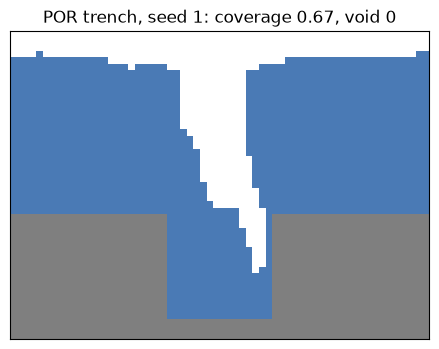

In [12]:
plot_trench(grid[:, x0 - 24: x1 + 24], voids[:, x0 - 24: x1 + 24],
            title=f"POR trench, seed 1: coverage {project['step_coverage']:.2f}, void {project['trench_void_area']}")
plt.show()

**What to notice:** every number matches `tr.measure`. With seed 1 this wafer has no trench void and coverage 0.67,
the same values `results/por_yield/data.csv` records for the trench POR with seed 1 (notebook 5 checks this
systematically). The white slot above the trench centre still opens to the top, so it is not a void.

## 7. Scaling up: four temperatures side by side

The same picture as `results/phase4_cross_sections/figure.png` (`scripts/run_phase4.py`, default 12 × 16 trench,
seed 42, 24 ML). Colours: white empty, grey substrate, blue film, red void.

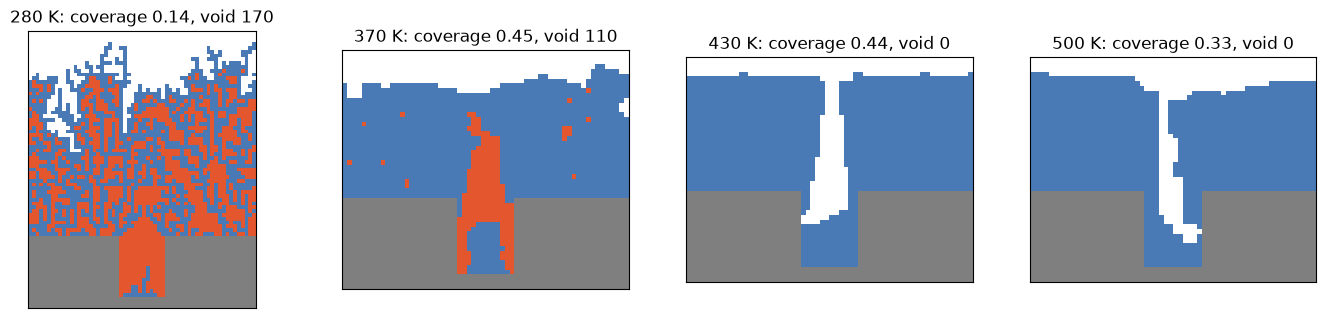

In [13]:
base = tr.TrenchSettings()
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, T in zip(axes, (280.0, 370.0, 430.0, 500.0)):
    s = tr.TrenchSettings(**{**asdict(base), "temperature": T})
    g = tr.grow(s); m = tr.measure(g, s); x0, x1 = s.trench_x
    plot_trench(g[:, x0 - 24: x1 + 24], tr.find_voids(g)[:, x0 - 24: x1 + 24], ax=ax,
                title=f"{T:g} K: coverage {m['step_coverage']:.2f}, void {m['trench_void_area']}")
plt.show()

**What to notice:**
* **280 K**: sticky, porous film (red pores everywhere count toward `total_void_area`) and the trench seals almost at
  once.
* **370 K**: dense film, but the overhangs still close over a void.
* **430 K and 500 K**: atoms reach the corners and the floor, and the trench mostly fills; a narrow seam can stay open
  to the surface (not a void by definition).

### Animation of one run

`scripts/run_phase4.py::growth_frames` deposits in chunks and snapshots after each one; `plotting.animate_trench`
turns the snapshots into an animation and `gif_bytes` renders it in memory. Here: 370 K, 25 frames.

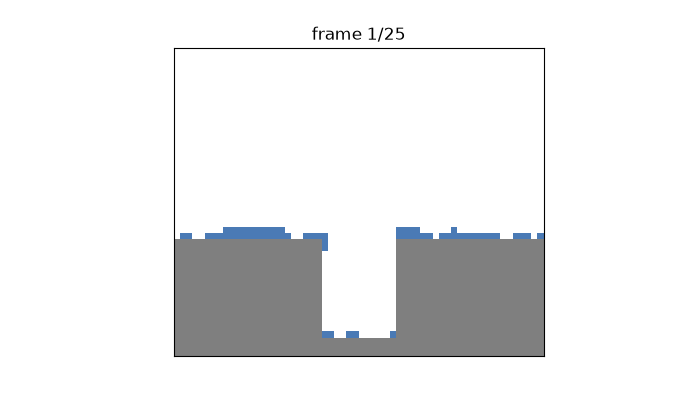

In [14]:
from IPython.display import Image
from thin_film.plotting import animate_trench, gif_bytes

s = tr.TrenchSettings(**{**asdict(base), "temperature": 370.0})
grid, (eps, hops) = tr.make_trench(s), s.thermal()
x0, x1 = s.trench_x
frames = []
for k in range(25):
    tr.deposit(grid, int(s.n_monolayers * s.width / 25), eps, hops, k)
    frames.append(trench_image(grid, tr.find_voids(grid))[:, x0 - 24: x1 + 24])
anim = animate_trench(frames); plt.close()
Image(data=gif_bytes(anim))

## 8. Sweeps: temperature and trench width

`tr.run_ensemble(settings)` grows `n_runs` wafers with seeds derived from the master seed and averages `measure`. It
adds standard errors and `void_probability` = fraction of runs with any trench void. `tr.sweep(settings, field,
values)` repeats that for each value of one setting. Both sweeps below are full size and must reproduce the saved
CSVs exactly.

### 8a. Temperature (12 × 16 trench, 1 ML/s)

1.9 s
identical to results/phase4_temperature_sweep/data.csv: True


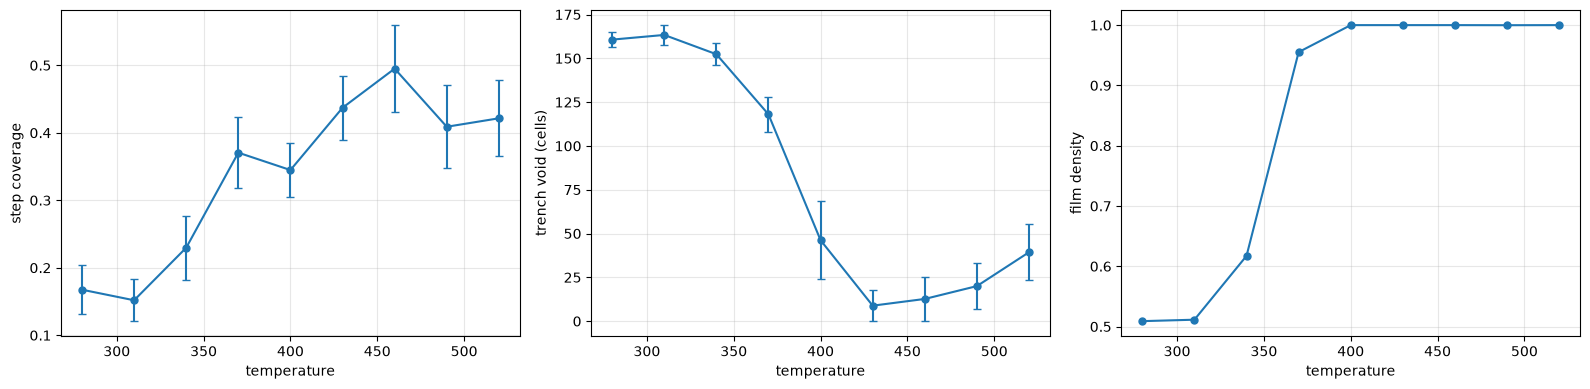

,temperature,hops_per_atom,step_coverage,trench_void_area,void_probability,film_density
0,280,0.040,0.168,160.667,1.000,0.509
1,310,0.987,0.152,163.333,1.000,0.511
2,340,13.858,0.230,152.333,1.000,0.617
3,370,126.818,0.371,118.000,1.000,0.955
4,400,832.614,0.345,46.167,0.500,1.000
5,430,3000.000,0.437,8.833,0.167,1.000
6,460,3000.000,0.495,12.667,0.167,1.000
7,490,3000.000,0.409,20.000,0.333,1.000
8,520,3000.000,0.421,39.333,0.667,1.000


In [15]:
t0 = time.perf_counter()
t_df = tr.sweep(base, "temperature", np.arange(280, 521, 30))
print(f"{time.perf_counter() - t0:.1f} s")
_, t_saved = load_saved("phase4_temperature_sweep")
print("identical to results/phase4_temperature_sweep/data.csv:",
      all(np.allclose(t_df[c], t_saved[c]) for c in ("step_coverage", "trench_void_area", "film_density")))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_sweep(t_df, "temperature", "step_coverage", "step_coverage_sem", ax=axes[0], ylabel="step coverage")
plot_sweep(t_df, "temperature", "trench_void_area", "trench_void_area_sem", ax=axes[1], ylabel="trench void (cells)")
plot_sweep(t_df, "temperature", "film_density", ax=axes[2], ylabel="film density")
plt.tight_layout(); plt.show()
t_df[["temperature", "hops_per_atom", "step_coverage", "trench_void_area", "void_probability", "film_density"]].round(3)

**What to notice** (saved values, 6 runs each): at 280 K the film is about half dense (0.51), coverage is 0.17 and
every run traps a big void (about 161 cells). At 370 K the film is dense (0.96) but every run still voids (118 cells).
From 400 K voids shrink sharply (46 cells, then 8.8 at 430 K, where 1 run in 6 had a void). The hops reach the 3000
cap at 430 K. Above that the void area rises again in this table (12.7, 20, 39 cells at 460, 490, 520 K), which
the README attributes to the hop cap; Part 9 checks that.

### 8b. Trench width (depth 16) at 370 K and 450 K

The **aspect ratio** is depth ÷ width: high aspect ratio = deep and narrow.

3.6 s
identical to results/phase4_width_sweep/data.csv: True


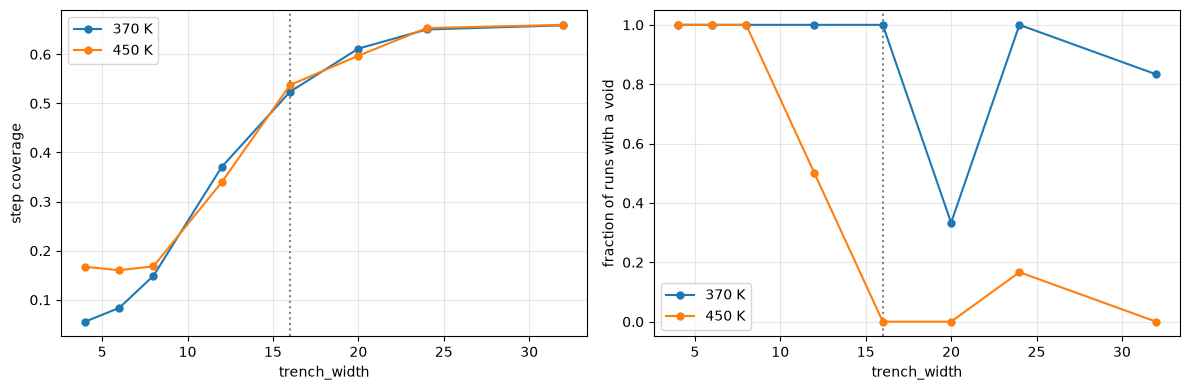

temperature,370.0,450.0
trench_width,,
4,1.00,1.00
6,1.00,1.00
8,1.00,1.00
12,1.00,0.50
16,1.00,0.00
20,0.33,0.00
24,1.00,0.17
32,0.83,0.00


In [16]:
t0 = time.perf_counter()
WIDTHS = [4, 6, 8, 12, 16, 20, 24, 32]
w_df = pd.concat([tr.sweep(tr.TrenchSettings(**{**asdict(base), "temperature": T}), "trench_width", WIDTHS).assign(temperature=T)
                  for T in (370.0, 450.0)], ignore_index=True)
print(f"{time.perf_counter() - t0:.1f} s")
_, w_saved = load_saved("phase4_width_sweep")
print("identical to results/phase4_width_sweep/data.csv:", np.allclose(w_df["step_coverage"], w_saved["step_coverage"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for T, d in w_df.groupby("temperature"):
    plot_sweep(d, "trench_width", "step_coverage", ax=axes[0], label=f"{T:g} K", ylabel="step coverage")
    plot_sweep(d, "trench_width", "void_probability", ax=axes[1], label=f"{T:g} K", ylabel="fraction of runs with a void")
for ax in axes: ax.axvline(16, color="grey", ls=":"); ax.legend()
plt.tight_layout(); plt.show()
w_df.pivot(index="trench_width", columns="temperature", values="void_probability").round(2)

**What to notice** (saved values): at 450 K trenches 4, 6 and 8 wide (aspect ratio 2 to 4) void in every run;
widths 16, 20 and 32 never do, and width 24 voided in 1 run of 6. At 370 K almost every width voids. The grey line
marks width = depth. **Geometry first, temperature second:** in a narrow trench the two corners are so close that
the overhangs meet after a few layers, before diffusing atoms can fill the bottom.

## 9. The hop cap: what it does, and a check of the README's claim

Hop counts are capped (`max_hops = 3000` per atom) to bound run time. The README and report say the void upturn above
about 460 K "is caused by this cap: hops stop increasing while bonds keep weakening". Two checks, with **24 runs**
per point instead of 6 (seed 7, so a different sample from the saved sweep): the default cap vs a cap 10 times
higher. This was written for this notebook; it is not one of the project's scripts.

In [17]:
t0 = time.perf_counter()
rows = []
for T in (430.0, 520.0):
    for cap in (3000, 30000):
        r = tr.run_ensemble(tr.TrenchSettings(temperature=T, max_hops=cap, n_runs=24, seed=7))
        rows.append({"temperature": T, "max_hops": cap, "hops_per_atom": tr.TrenchSettings(temperature=T, max_hops=cap).thermal()[1],
                     "void_area": r["trench_void_area"], "void_area_sem": r["trench_void_area_sem"],
                     "void_probability": r["void_probability"], "step_coverage": r["step_coverage"]})
print(f"{time.perf_counter() - t0:.1f} s")
pd.DataFrame(rows).round(2)

23.4 s


,temperature,max_hops,hops_per_atom,void_area,void_area_sem,void_probability,step_coverage
0,430.0,3000,3000.00,20.71,6.20,0.38,0.43
1,430.0,30000,4204.06,16.04,6.60,0.21,0.45
2,520.0,3000,3000.00,20.42,6.03,0.38,0.45
3,520.0,30000,30000.00,11.79,3.22,0.50,0.56


**What to notice:** read the table above. With 24 runs and the default cap, the void area at 520 K is about the same
as at 430 K (both around 20 cells, with standard errors of about 6), so the larger sample does not show a clear
upturn; the saved 6-run sweep's rise to 39 cells at 520 K is within its own error bars (±16). Raising the cap
tenfold at 520 K lowers the mean void area and raises coverage somewhat, but roughly half the runs still trap a
void. So the cap matters, but for this 12-wide trench it is not the only reason voids persist when hot. (This is
listed as a discrepancy in the notebook-rewrite notes; the report files were not changed.)

## 10. The process window and the trench POR

`process_window()` in `scripts/run_phase4.py` tries 3 widths (8, 12, 16) × 8 temperatures (380 to 520 K) × 4 rates
(0.1 to 100 ML/s) = 96 recipes, 8 runs each, at depth 16. We plot the saved grid for each width, then recompute the
POR row to check it.

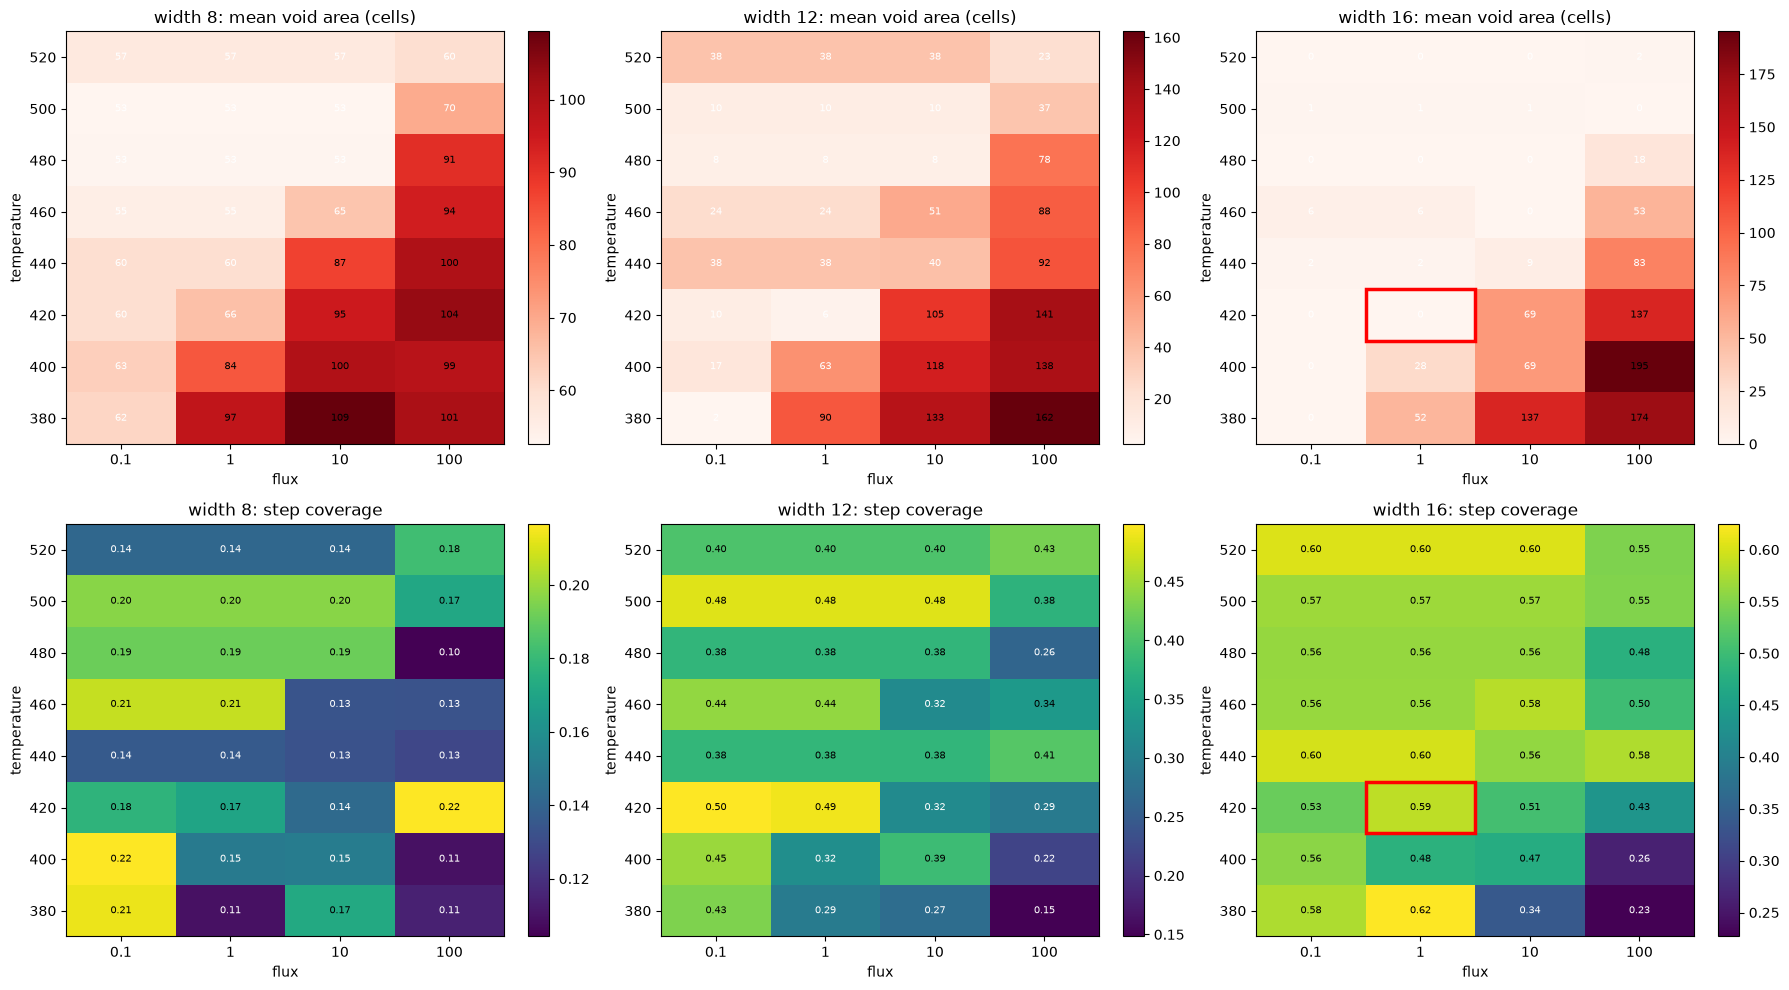

smallest mean void at width 8: 52.625 cells


In [18]:
_, pw = load_saved("phase4_process_window")
por = IDEAL["trench"]["settings"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for k, w in enumerate([8, 12, 16]):
    d = pw[pw["trench_width"] == w]
    hl = (por["temperature"], por["flux"]) if w == por["trench_width"] else None
    plot_heatmap(d.pivot(index="temperature", columns="flux", values="trench_void_area"), ax=axes[0, k],
                 title=f"width {w}: mean void area (cells)", fmt="{:.0f}", cmap="Reds", highlight=hl)
    plot_heatmap(d.pivot(index="temperature", columns="flux", values="step_coverage"), ax=axes[1, k],
                 title=f"width {w}: step coverage", highlight=hl)
plt.tight_layout(); plt.show()
print("smallest mean void at width 8:", pw[pw.trench_width == 8]["trench_void_area"].min(), "cells")

In [19]:
t0 = time.perf_counter()
check = pd.DataFrame([{"flux": f, **tr.run_ensemble(tr.TrenchSettings(trench_width=16, temperature=420.0, flux=f, n_runs=8))}
                      for f in (0.1, 1.0, 10.0, 100.0)])
print(f"{time.perf_counter() - t0:.1f} s")
saved_row = pw[(pw.trench_width == 16) & (pw.temperature == 420)]
print("recomputed void area:", check["trench_void_area"].round(3).tolist(), "| saved:", saved_row["trench_void_area"].round(3).tolist())
print("recomputed coverage :", check["step_coverage"].round(3).tolist(), "| saved:", saved_row["step_coverage"].round(3).tolist())

1.1 s
recomputed void area: [0.125, 0.0, 69.25, 136.625] | saved: [0.125, 0.0, 69.25, 136.625]
recomputed coverage : [0.534, 0.585, 0.506, 0.435] | saved: [0.534, 0.585, 0.506, 0.435]


In [20]:
print(json.dumps(IDEAL["trench"]["settings"]))
print()
print(IDEAL["trench"]["why"])

{"temperature": 420, "flux": 1.0, "trench_width": 16, "trench_depth": 16, "n_monolayers": 24}

Void-free in the grid search (void 0, coverage 0.59), within noise of the highest coverage found (0.60 at 520 K) but 100 K cooler. Single wafers vary: 24 of 30 seeds pass the spec (the rest have coverage just under 0.50 or a 1-6 cell void), so expect ~80% yield. Geometry matters most: a trench must be about as wide as it is deep. At width 8 / depth 16 no temperature or rate avoids a void. 460 K at 10 ML/s is also void-free on average and 10x faster, but only 16 of 30 wafers pass.


**What to notice:** at width 8 no recipe is void-free (the smallest mean void is about 53 cells). At width 16 a band
of recipes is void-free or nearly so. The red box, **420 K at 1 ML/s**, has mean void 0 and coverage 0.585 in the
saved grid, close to the best coverage (0.60) but 100 K cooler than the best cell at 520 K. Note that several
hotter width-16 cells have small non-zero mean voids (for example 2.0 at 440 K and 6.4 at 460 K at 1 ML/s, each from
1 run of 8), so "void-free above ~430 K" in the README is true for most runs, not every run.

An average of 0 over 8 runs does not guarantee every wafer passes; notebook 5 runs the POR on 30 single wafers.

## 11. How the `results/phase4_*` folders are produced

`PYTHONPATH=src .venv/bin/python scripts/run_phase4.py` runs `main()` and `process_window()` (not run here):

| Saved folder | What | Notebook part |
|---|---|---|
| `results/phase4_temperature_sweep/` | `sweep(base, "temperature", 280..520)` and a 3-panel figure | 8a |
| `results/phase4_width_sweep/` | width sweep at 370 and 450 K | 8b |
| `results/phase4_cross_sections/` | the 4-temperature gallery figure, plus `growth_280K.gif` and `growth_470K.gif` made with `growth_frames` + `animate_trench` | 7 |
| `results/phase4_process_window/` | the 96-recipe grid and heatmaps with the POR boxed | 10 |

Tests in `tests/test_trench.py` cover the initial geometry, the two flood-fill grids from Part 5, atom conservation,
"cold narrow trench always voids", "hot wide trench nearly fills" and "heating improves coverage and density";
`tests/test_ideal.py` checks that the POR is void-free with coverage above 0.5 over 8 runs.

## 12. Recap and exercises

### What we learned
* The trench model is a 2D grid; atoms fall straight down and stick on first contact below or beside, which grows
  overhangs from the corners.
* Heat gives the newest atom hops toward better-bonded empty cells, which fills the trench from the bottom.
* A void is an empty cell that a BFS flood fill from the top cannot reach; open seams are not voids.
* Step coverage compares mass thickness at the trench bottom (central third) with the far flat field.
* Aspect ratio dominates: trenches 2× deeper than wide void at every recipe tried; trenches as wide as deep fill
  when hot. The POR is 16 × 16 at 420 K and 1 ML/s.

### Step → module/function → script map

| Step | Module / function | Script / test |
|---|---|---|
| build the trench | `trench.make_trench`, `TrenchSettings.height`, `trench_x` | `tests/test_trench.py::test_initial_geometry` |
| fall, stick, hop | `trench.deposit` (Numba), `_coordination` | `tests/test_trench.py::test_atoms_conserved` |
| find voids | `trench.find_voids` (BFS, Numba) | `tests/test_trench.py` flood-fill tests |
| metrics | `trench.measure` | |
| one wafer / ensemble / sweep | `trench.grow`, `run_ensemble`, `sweep` | `scripts/run_phase4.py::main` |
| process window | loops over `run_ensemble` | `scripts/run_phase4.py::process_window` |
| POR | `ideal.IDEAL["trench"]` | `tests/test_ideal.py` |
| pictures | `plotting.plot_trench`, `trench_image`, `animate_trench`, `plot_heatmap` | |

### Try changing X and see Y
1. In Part 4, change the falling rule so atoms stick only on contact **below** (delete the two side checks in
   `my_deposit`). Do overhangs and voids still form?
2. Make the tiny trench 8 wide instead of 4 at 250 K. Does it still seal?
3. In Part 5, open the pocket by setting `g[4, 3] = EMPTY`. How many voids now?
4. Run the POR with `trench_depth=24` (aspect ratio 1.5). Is it still void-free?
5. Re-run Part 9 at 460 K and 490 K, or with `n_runs=48`. Does a trend appear?

**Next:** notebook 5 turns these recipes into fab-style specs, checks them wafer by wafer, and shows how the app
records and replays a run.